In [78]:
%env CUDA_DEVICE_ORDER=PCI_BUS_ID
%env CUDA_VISIBLE_DEVICES=0
%pylab inline
%load_ext autoreload
%autoreload 2

env: CUDA_DEVICE_ORDER=PCI_BUS_ID
env: CUDA_VISIBLE_DEVICES=0
%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import json
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
import os
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.pyplot as plt
import matplotlib as mpl
from openTSNE import TSNE
import colorcet as cc

/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from ssl_neuron.datasets import GraphDataset
from ssl_neuron.utils import plot_neuron, plot_tsne, neighbors_to_adjacency_torch, compute_eig_lapl_torch_batch
from ssl_neuron.graphdino import create_model

In [36]:
TRIAL = "trial5"

#### Load config

In [37]:
config = json.load(open(f'../configs/{TRIAL}.json'))

#### Load model + checkpoint

In [38]:
os.path.join(config['data']['path'], 'skeleton/720575940537162675/features.npy')

'/gpfs01/berens/user/pgivehchian/data/skeleton/720575940537162675/features.npy'

In [39]:
cell_meta = pd.read_csv(os.path.join(config['data']['path'], 'cell_meta.csv'))
cell_meta['cell_id'] = cell_meta['cell_id'].astype(str)

In [40]:
cell_meta

,cell_id,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,cellclass_final,valid_cellclass_final,valid_status,celltype_final,valid_celltype_final,celltype_final_decision,soma_x_um,soma_y_um,soma_z_um
0,720575940537162675,623.088321,271.935098,-21.628196,9054,8096,958,0,RGC,True,True,NaN,False,NaN,623.088,271.935,-21.6282
1,720575940537274291,483.576538,891.599123,-14.109626,5112,3943,1169,0,RGC,True,True,ON alpha,True,both_strong,483.577,891.599,-14.1096
2,720575940537284275,477.293864,607.582202,-18.812998,6950,6137,813,0,RGC,True,True,Sustained suppressed-by-contrast strong surrou...,True,both_weak,477.294,607.582,-18.8130
3,720575940537313971,778.958349,719.019178,-14.450323,8642,7627,1015,0,RGC,True,True,ON delayed,True,both_strong,778.958,719.019,-14.4503
4,720575940537343155,283.318443,409.646856,-16.305329,9935,8934,1001,0,RGC,True,True,OFF vertical OS - asymmetric,True,both_strong,283.318,409.647,-16.3053
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3685,720575940589082516,271.145212,1050.133062,-13.881681,9780,9657,123,0,RGC,True,True,NaN,False,NaN,271.145,1050.130,-13.8817
3686,720575940589088148,281.992055,1067.835937,-14.430131,17577,14828,2749,0,RGC,True,True,NaN,False,NaN,281.992,1067.840,-14.4301
3687,720575940589111700,851.058152,1070.755962,-14.051774,13661,11003,2658,0,RGC,True,True,HD2,True,both_strong,851.058,1070.760,-14.0518
3688,720575940589184404,1036.643098,993.958841,-13.925180,16997,15377,1620,0,RGC,True,True,HD1,True,both_weak,1036.640,993.959,-13.9252


In [41]:
model = create_model(config)

In [42]:
state_dict = torch.load(f'../ckpts/{TRIAL}.pt')

In [43]:
model.load_state_dict(state_dict)

<All keys matched successfully>

In [44]:
model.eval()
model.cuda();

#### Load dataset

In [13]:
dset = GraphDataset(config, mode='all')

  0%|          | 0/3690 [00:00<?, ?it/s]

100%|██████████| 3690/3690 [02:00<00:00, 30.59it/s]


In [14]:
feat, neigh, cell_id = dset.__getsingleitem__(0)

In [15]:
feat.shape, len(neigh)

((1000, 3), 1000)

#### Plot neuron

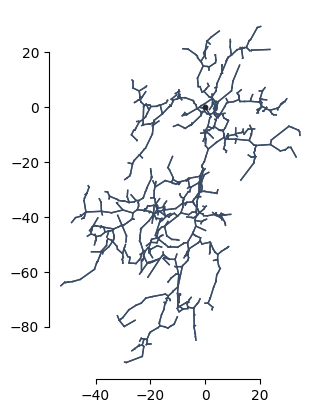

In [92]:
plot_neuron(neigh, feat)

#### Run inference

In [93]:
latents = np.zeros((dset.num_samples, config['model']['dim']))

cell_meta['latent'] = pd.Series(
    [None] * len(cell_meta),
    index=cell_meta.index,
    dtype=object
)

cell_meta['cell_id'] = cell_meta['cell_id'].astype(str)

for i in tqdm(range(dset.num_samples)):
    feat, neigh, cell_id = dset.__getsingleitem__(i)
    cell_id = str(cell_id)

    adj = neighbors_to_adjacency_torch(
        neigh, list(neigh.keys())
    ).float().cuda()[None, :]

    lapl = compute_eig_lapl_torch_batch(
        adj,
        pos_enc_dim=config['model']['pos_dim']
    ).float().cuda()

    feat = torch.from_numpy(feat).float().cuda()[None, :]

    with torch.no_grad():
        embedding = model.student_encoder.forward(feat, adj, lapl)[0]
        embedding = embedding.cpu().numpy().squeeze()

    latents[i] = embedding

    mask = cell_meta['cell_id'] == cell_id

    for idx in cell_meta.index[mask]:
        cell_meta.at[idx, 'latent'] = embedding

print("\nEmbedding extraction complete!")
print("Latents matrix shape:", latents.shape)
print("Rows with embeddings:", cell_meta['latent'].notna().sum())


  0%|          | 0/3690 [00:00<?, ?it/s]

100%|██████████| 3690/3690 [04:03<00:00, 15.18it/s]


Embedding extraction complete!
Latents matrix shape: (3690, 32)
Rows with embeddings: 3690


In [94]:
cell_meta.to_csv(
    os.path.join(config['trainer']['latents_dir'], f'{TRIAL}.csv'),
    index=False
)

<ErrorbarContainer object of 3 artists>

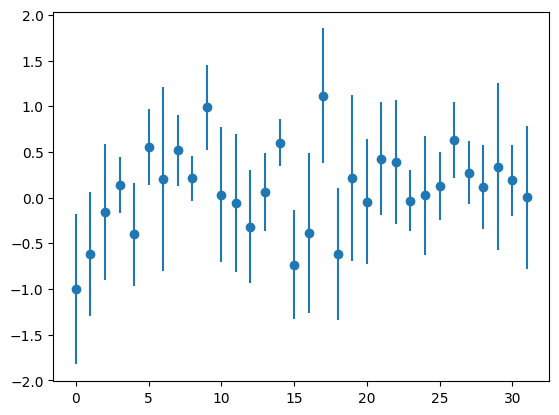

In [95]:
plt.scatter(np.arange(config['model']['dim']), latents.mean(axis=0))

plt.errorbar(np.arange(config['model']['dim']), latents.mean(axis=0), yerr = latents.std(axis=0), fmt='none')

In [45]:
cell_meta = pd.read_csv(os.path.join(config['trainer']['latents_dir'], f'{TRIAL}.csv'))

In [46]:
cell_meta['latent'] = cell_meta['latent'].apply(
    lambda x: np.fromstring(x.strip('[]'), sep=' ')
)

cell_meta['latent']

0       [-0.65036905, -0.4284796, 0.12980741, 1.293734...
1       [0.19348583, 0.29875153, 2.1343093, -1.5394232...
2       [0.64811957, -0.19985358, 0.49069244, 0.238396...
3       [0.8154574, 0.05587818, 2.21842, -0.6756907, 1...
4       [0.02263346, -0.57899034, -0.01602254, 0.96836...
                              ...                        
3685    [0.3796096, -0.0794539, 1.8780956, -0.8067027,...
3686    [0.7180398, -0.3244244, 1.78412, -0.40581793, ...
3687    [-0.51480985, 0.14757237, 1.6501734, -0.332935...
3688    [-0.27872893, 0.04942784, 1.6043613, -0.238960...
3689    [0.25582623, -0.15610723, -0.028115891, 0.7305...
Name: latent, Length: 3690, dtype: object

In [47]:
def get_celltype_colors(cell_meta):
    celltypes = sorted(cell_meta['celltype_final'].dropna().unique())

    colors = cc.glasbey[:len(celltypes)]

    color_dict = dict(zip(celltypes, colors))

    return color_dict

color_dict = get_celltype_colors(cell_meta)

In [48]:
def plot_tsne(
    cell_meta,
    unknown_labels=True,
    color_by='celltype',
    perplexity=30,
    random=True,
    color_dict=None
):

    if unknown_labels:
        plot_df = cell_meta.copy()
    else:
        plot_df = cell_meta[cell_meta['celltype_final'].notna()].copy()

    X = np.stack(plot_df['latent'].values).astype(np.float32)

    print("Embedding shape:", X.shape)
    print("Embedding dtype:", X.dtype)

    # Run t-SNE
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        initialization='random',
        learning_rate=200.0,
        n_jobs=-1
    )

    X_tsne = np.array(tsne.fit(X))

    plot_df['TSNE1'] = X_tsne[:, 0]
    plot_df['TSNE2'] = X_tsne[:, 1]

    if random:
        plot_df = plot_df.sample(frac=1).reset_index(drop=True)

    fig, ax = plt.subplots(
        figsize=(8, 5) if color_by != 'celltype' else (12, 5)
    )

    # 1. Color by cell type
    if color_by == 'celltype':

        if color_dict is None:
            color_dict = get_celltype_colors(plot_df)

        point_colors = plot_df['celltype_final'].map(color_dict)

        if unknown_labels:
            point_colors = point_colors.fillna('lightgrey')

        ax.scatter(
            plot_df['TSNE1'],
            plot_df['TSNE2'],
            c=point_colors,
            s=15,
            alpha=0.8,
            zorder=2
        )

        from matplotlib.lines import Line2D

        legend_elements = [
            Line2D(
                [0], [0],
                marker='o',
                color='w',
                label=str(celltype),
                markerfacecolor=color,
                markersize=6
            )
            for celltype, color in color_dict.items()
        ]

        if unknown_labels:
            legend_elements.append(
                Line2D(
                    [0], [0],
                    marker='o',
                    color='w',
                    label='Unknown',
                    markerfacecolor='lightgrey',
                    markersize=6
                )
            )

        ax.legend(
            handles=legend_elements,
            title='Cell Type',
            bbox_to_anchor=(1.02, 1),
            loc='upper left',
            ncol=2,
            fontsize=8,
            markerscale=1.5
        )

    # 2. Color by a continuous variable
    elif color_by in plot_df.columns and color_by != 'none':

        values = plot_df[color_by].to_numpy(dtype=float)

        vmin, vmax = np.nanpercentile(values, [2, 98])
        vcenter = np.nanmean(values)

        norm = TwoSlopeNorm(
            vmin=vmin,
            vcenter=vcenter,
            vmax=vmax
        )

        cmap = mpl.colormaps['RdBu_r']

        if random:
            order = np.random.permutation(len(plot_df))
        else:
            order = np.arange(len(plot_df))

        sc = ax.scatter(
            plot_df['TSNE1'].to_numpy()[order],
            plot_df['TSNE2'].to_numpy()[order],
            c=values[order],
            cmap=cmap,
            norm=norm,
            s=15,
            alpha=0.8
        )

        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label(color_by)

    # 3. Single color
    elif color_by == 'none':

        ax.scatter(
            plot_df['TSNE1'],
            plot_df['TSNE2'],
            color='steelblue',
            s=15,
            alpha=0.7
        )

    else:
        raise ValueError(
            f"Unknown color_by='{color_by}'. "
            "Use 'celltype', 'none', or a numerical column name."
        )

    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.set_title(f't-SNE of Neuron Embeddings (colored by {color_by})')

    plt.tight_layout()
    plt.show()

    return plot_df

Embedding shape: (3690, 32)
Embedding dtype: float32


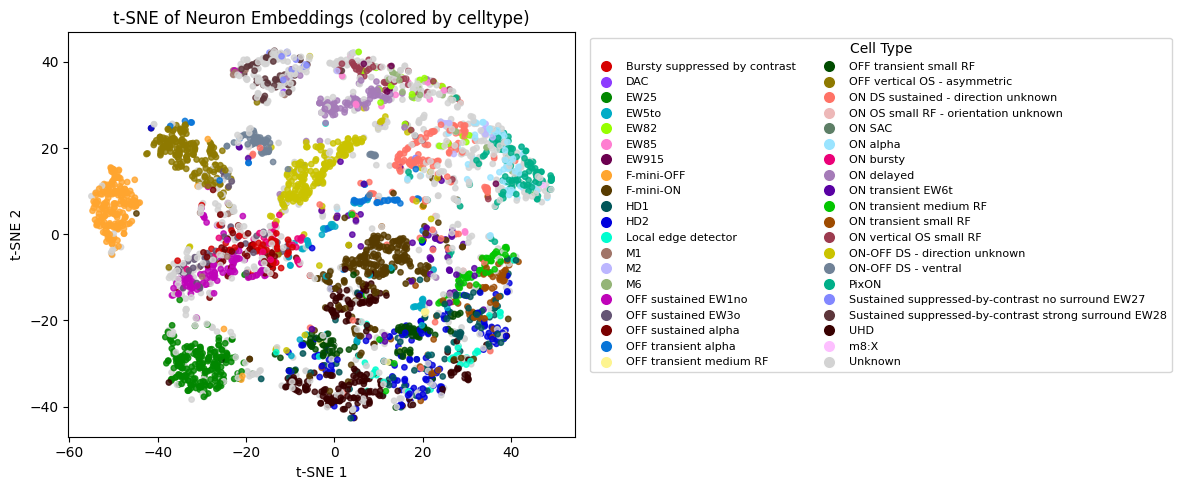

Embedding shape: (3690, 32)
Embedding dtype: float32


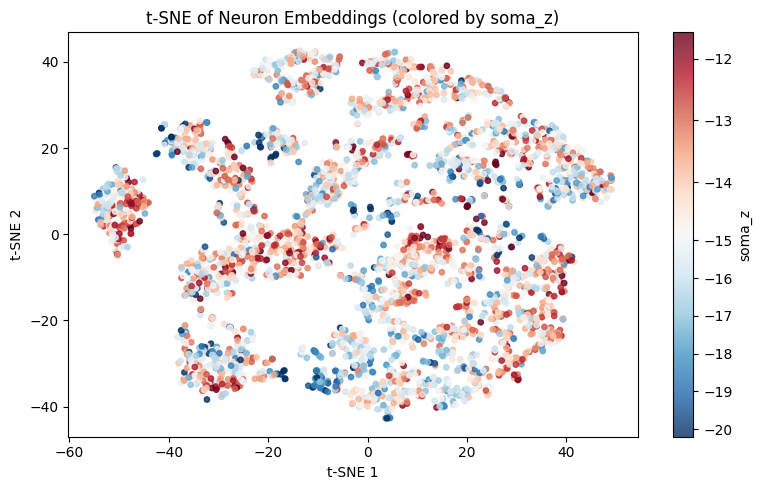

In [49]:
# plot_df = plot_tsne(cell_meta, unknown_labels=False, color_by='celltype')

plot_df = plot_tsne(cell_meta, unknown_labels=True, color_dict=color_dict, color_by='celltype')

# plot_df = plot_tsne(cell_meta, color_by='none')

plot_df = plot_tsne(cell_meta, color_dict=color_dict, color_by='soma_z')


Training losses:
[6.86194277 6.65358973 6.41996431 6.25195122 6.14831018 6.0330143
 5.93396759 5.7552247  5.53004646 5.13674021 4.69674444 4.34420919
 4.09417677 3.84723449 3.70480728 3.60728502 3.47252297 3.34855986
 3.23839784 3.14218378 3.02764463 2.86731648 2.73241639 2.56665421
 2.3893528  2.31221366 2.24176788 2.17881918 2.12245703 2.06997943
 2.02839541 1.92683625 1.82058632 1.76831436 1.69906688 1.63821328
 1.64176285 1.59989274 1.59653294 1.57438111 1.55343151 1.53770721
 1.48758447 1.50749493 1.48299706 1.44306302 1.44131351 1.46006691
 1.42298746 1.39013338 1.39039779 1.35267651 1.34986997 1.30760121
 1.31572318 1.28125584 1.26402187 1.25740528 1.23569798 1.18860483
 1.24294055 1.21858335 1.22366524 1.2040484  1.17239046 1.21004701
 1.19239855 1.1845721  1.17404091 1.14335978 1.13643587 1.14773762
 1.12972224 1.14051926 1.15196884 1.10509062 1.15074289 1.15618968
 1.16519427 1.16092741 1.19630623 1.19421947 1.19603729 1.20953381
 1.1820153  1.19622779 1.16314793 1.12449193 1

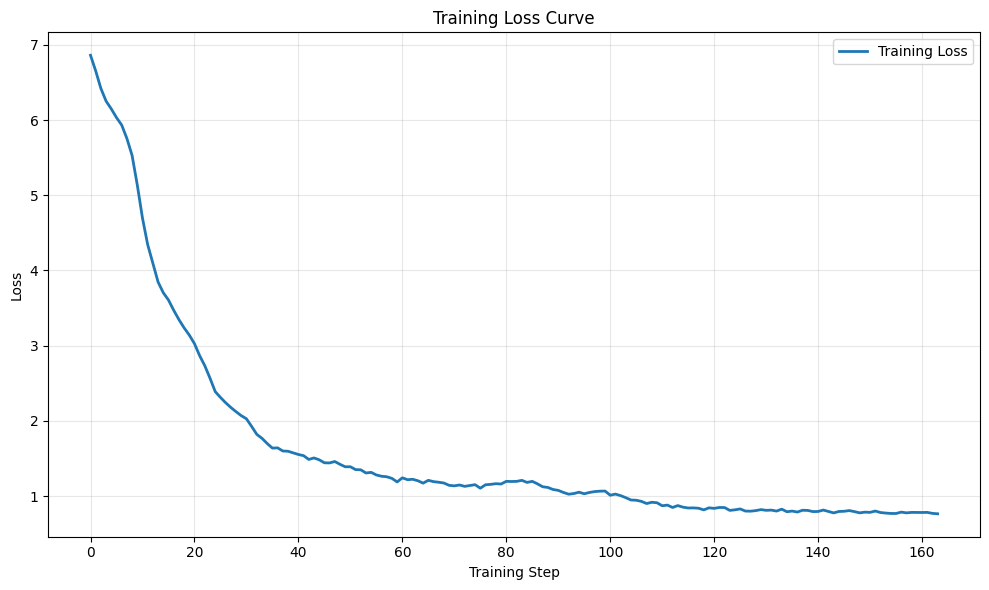

In [51]:
loss_path = Path("..") / Path(config['trainer']['losses_dir']) / Path(TRIAL) / "training_loss.npy"
losses = np.load(loss_path)

print("Training losses:")
print(losses)

print(f"Number of training steps: {len(losses)}")
print(f"Initial loss: {losses[0]:.6f}")
print(f"Final loss: {losses[-1]:.6f}")
print(f"Minimum loss: {np.min(losses):.6f}")

plt.figure(figsize=(10, 6))
plt.plot(losses, label="Training Loss", linewidth=2)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Data Analysis

### z means

In [52]:
z_means = []

for _, row in tqdm(cell_meta.iterrows(), total=len(cell_meta)):

    cell_id = int(row['cell_id'])

    feature_path = os.path.join(
        config['data']['path'],
        'skeletons',
        str(cell_id),
        'features.npy'
    )

    if os.path.exists(feature_path):

        features = np.load(feature_path)
        z_values = features[:, 2]
        z_mean = np.nanmean(z_values)

    else:
        print(f"Missing features: {cell_id}")
        z_mean = np.nan

    z_means.append(z_mean)

cell_meta['z_mean'] = z_means

100%|██████████| 3690/3690 [00:02<00:00, 1511.32it/s]


Embedding shape: (3690, 32)
Embedding dtype: float32


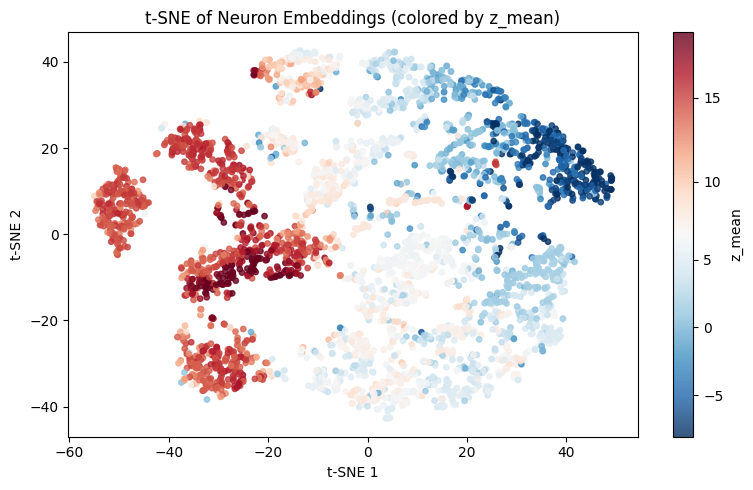

In [53]:
plot_df = plot_tsne(cell_meta, unknown_labels=True, color_by='z_mean')

Embedding shape: (3690, 32)
Embedding dtype: float32


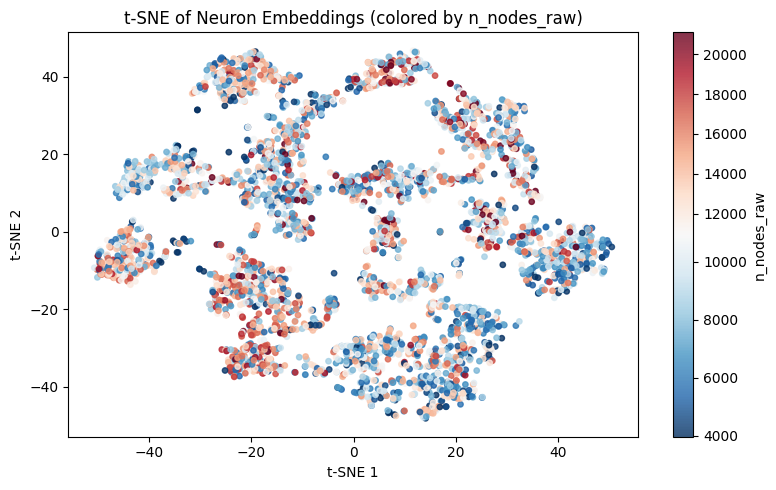

In [132]:
plot_df = plot_tsne(cell_meta, unknown_labels=True, color_by='n_nodes_raw')

In [156]:
overlapping_types = [
    "OFF sustained EW1no",
    "OFF sustained alpha",
    "OFF sustained EW3o",
    "ON bursty",
    "Bursty suppressed by contrast"
]

In [148]:
cell_meta.head()

,cell_id,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,cellclass_final,valid_cellclass_final,valid_status,celltype_final,valid_celltype_final,celltype_final_decision,soma_x_um,soma_y_um,soma_z_um,latent,z_mean
0,720575940537162675,623.088321,271.935098,-21.628196,9054,8096,958,0,RGC,True,True,NaN,False,NaN,623.088,271.935,-21.6282,"[-0.67341435, -0.5406292, -0.050600063, -0.203...",5.774054
1,720575940537274291,483.576538,891.599123,-14.109626,5112,3943,1169,0,RGC,True,True,ON alpha,True,both_strong,483.577,891.599,-14.1096,"[0.41959268, -1.8017517, -1.2318739, 0.4516849...",-4.730283
2,720575940537284275,477.293864,607.582202,-18.812998,6950,6137,813,0,RGC,True,True,Sustained suppressed-by-contrast strong surrou...,True,both_weak,477.294,607.582,-18.8130,"[-1.4684308, 0.46324295, 0.27300853, 0.1723688...",6.635349
3,720575940537313971,778.958349,719.019178,-14.450323,8642,7627,1015,0,RGC,True,True,ON delayed,True,both_strong,778.958,719.019,-14.4503,"[-1.3508973, -0.22374223, -0.31572115, 0.41185...",4.784226
4,720575940537343155,283.318443,409.646856,-16.305329,9935,8934,1001,0,RGC,True,True,OFF vertical OS - asymmetric,True,both_strong,283.318,409.647,-16.3053,"[-0.09832171, -0.73021144, 0.36961293, 0.03296...",15.894759


In [ ]:
on_bursty = cell_meta[cell_meta["celltype_final"] == "ON bursty"]

In [160]:
cell_meta[cell_meta["celltype_final"] == "OFF sustained EW1no"].head()

,cell_id,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,cellclass_final,valid_cellclass_final,valid_status,celltype_final,valid_celltype_final,celltype_final_decision,soma_x_um,soma_y_um,soma_z_um,latent,z_mean
47,720575940546176499,1056.567926,717.896308,-15.356864,14892,12316,2576,0,RGC,True,True,OFF sustained EW1no,True,both_strong,1056.570,717.896,-15.3569,"[-2.003943, 0.061876312, 1.6944834, 0.41724804...",18.395971
97,720575940547868345,577.145960,469.948925,-12.929788,8937,7920,1017,0,RGC,True,True,OFF sustained EW1no,True,both_strong,577.146,469.949,-12.9298,"[-2.2073257, -0.16739176, 1.5063401, 0.3524042...",17.660141
112,720575940548206982,383.374524,587.434864,-14.012903,6883,5861,1022,0,RGC,True,True,OFF sustained EW1no,True,both_strong,383.375,587.435,-14.0129,"[-2.3010192, -0.005031422, 1.6509145, 0.381200...",20.122328
137,720575940549250004,549.203545,494.998524,-14.434049,16135,14513,1622,0,RGC,True,True,OFF sustained EW1no,True,both_strong,549.204,494.999,-14.4340,"[-2.3151424, -0.28453517, 1.5813985, 0.4517015...",19.693958
308,720575940552077888,836.086046,1036.828400,-13.303650,15691,14671,1020,0,RGC,True,True,OFF sustained EW1no,True,classifier,836.086,1036.830,-13.3036,"[-1.3778712, -0.8619991, 1.3039252, 0.40759686...",20.342571


In [158]:
cell_meta[cell_meta["celltype_final"] == "OFF sustained alpha"].head()

,cell_id,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,cellclass_final,valid_cellclass_final,valid_status,celltype_final,valid_celltype_final,celltype_final_decision,soma_x_um,soma_y_um,soma_z_um,latent,z_mean
94,720575940547434425,240.276180,888.000810,-13.314395,7648,6576,1072,0,RGC,True,True,OFF sustained alpha,True,both_strong,240.276,888.001,-13.3144,"[-1.9761114, -0.7792328, 0.9927183, 0.42309144...",16.973698
240,720575940551332576,587.672209,900.864144,-14.012386,13811,13811,0,0,RGC,True,True,OFF sustained alpha,True,both_strong,587.672,900.864,-14.0124,"[-1.9048916, -0.5863258, 1.1251289, 0.75572705...",16.753359
316,720575940552179071,556.213952,342.770503,-15.720683,13530,12531,999,0,RGC,True,True,OFF sustained alpha,True,both_strong,556.214,342.771,-15.7207,"[-2.0795698, -0.7690989, 0.9863171, 0.36285505...",16.743586
463,720575940553686131,543.385120,945.003302,-14.503959,11190,11190,0,0,RGC,True,True,OFF sustained alpha,True,both_weak,543.385,945.003,-14.5040,"[-1.9703608, -0.5199645, 1.1783231, 0.5373971,...",17.392076
492,720575940553987159,783.876337,602.953849,-14.617924,11369,10353,1016,0,RGC,True,True,OFF sustained alpha,True,both_strong,783.876,602.954,-14.6179,"[-1.5005811, -0.7659238, 1.0601095, 0.6464118,...",16.553514


In [150]:
on_bursty.head()

,cell_id,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,cellclass_final,valid_cellclass_final,valid_status,celltype_final,valid_celltype_final,celltype_final_decision,soma_x_um,soma_y_um,soma_z_um,latent,z_mean
128,720575940548714374,926.598320,477.974888,-14.044615,16342,15088,1254,0,RGC,True,True,ON bursty,True,both_weak,926.598,477.975,-14.0446,"[-1.7899822, -0.8207405, 0.6488267, 0.41187033...",12.993882
140,720575940549425364,437.093475,971.682348,-16.693945,14128,13737,391,0,RGC,True,True,ON bursty,True,both_weak,437.093,971.682,-16.6939,"[-1.8870255, -0.8555189, 0.63373, 0.31600243, ...",10.264953
354,720575940552609114,892.559457,386.301527,-13.789387,18404,17202,1202,0,RGC,True,True,ON bursty,True,both_strong,892.559,386.302,-13.7894,"[-1.9184815, -0.69479454, 0.41459048, 0.187236...",11.831037
467,720575940553727139,437.251306,829.031054,-17.192983,5719,4800,919,0,RGC,True,True,ON bursty,True,both_weak,437.251,829.031,-17.1930,"[-1.6580175, -0.7273074, 0.92227775, 0.5428571...",12.463758
595,720575940554971674,623.242806,334.222111,-18.496557,14854,13876,978,0,RGC,True,True,ON bursty,True,both_weak,623.243,334.222,-18.4966,"[-1.7616619, -0.84823996, 0.8415809, 0.3452145...",12.484303


In [149]:
# for key, value in dset.cells.items():
#     print(f"\n{key}:")
#     try:
#         print(value[:5])
#     except (TypeError, IndexError):
#         print(value)

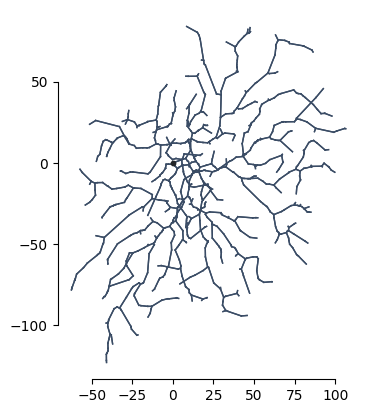

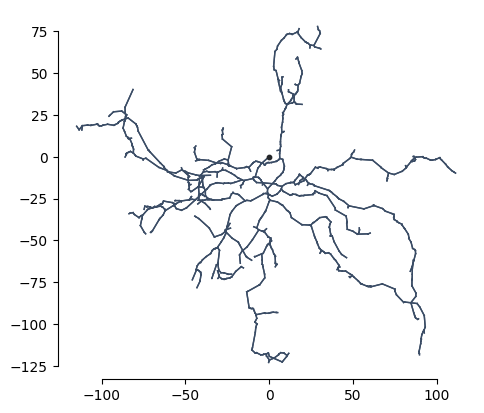

In [164]:
feat, neigh, cell_id = dset.__getsingleitem__(47)
plot_neuron(neigh, feat)

feat, neigh, cell_id = dset.__getsingleitem__(97)
plot_neuron(neigh, feat)

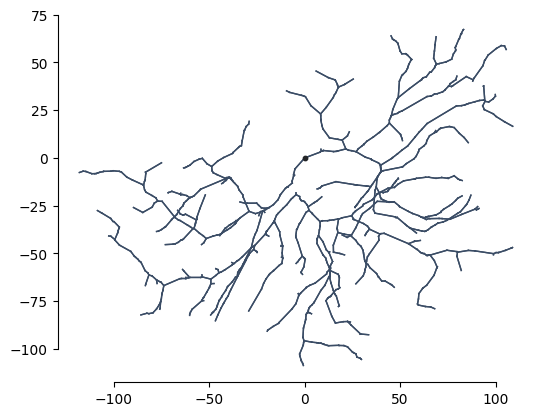

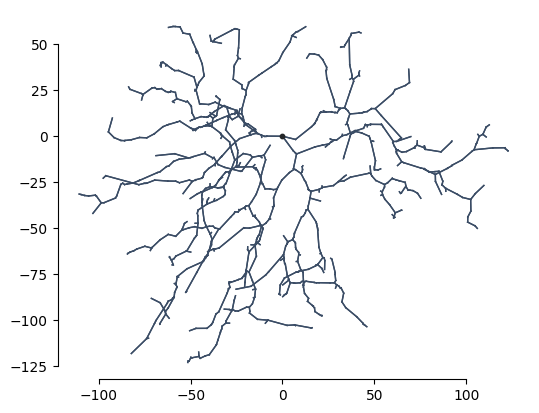

In [159]:
feat, neigh, cell_id = dset.__getsingleitem__(94)
plot_neuron(neigh, feat)

feat, neigh, cell_id = dset.__getsingleitem__(240)
plot_neuron(neigh, feat)

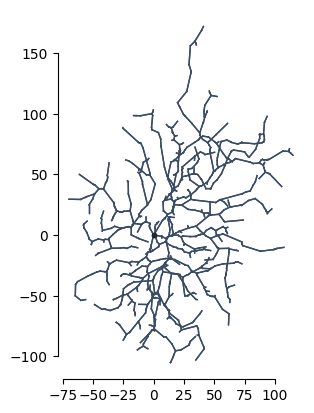

In [153]:
feat, neigh, cell_id = dset.__getsingleitem__(595)
plot_neuron(neigh, feat)

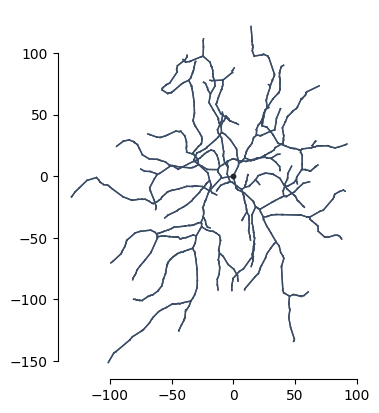

In [151]:
feat, neigh, cell_id = dset.__getsingleitem__(128)
plot_neuron(neigh, feat)

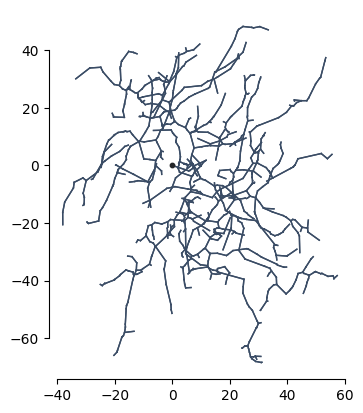

In [152]:
feat, neigh, cell_id = dset.__getsingleitem__(140)
plot_neuron(neigh, feat)